In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_circles # swap to make_circles if you want
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression




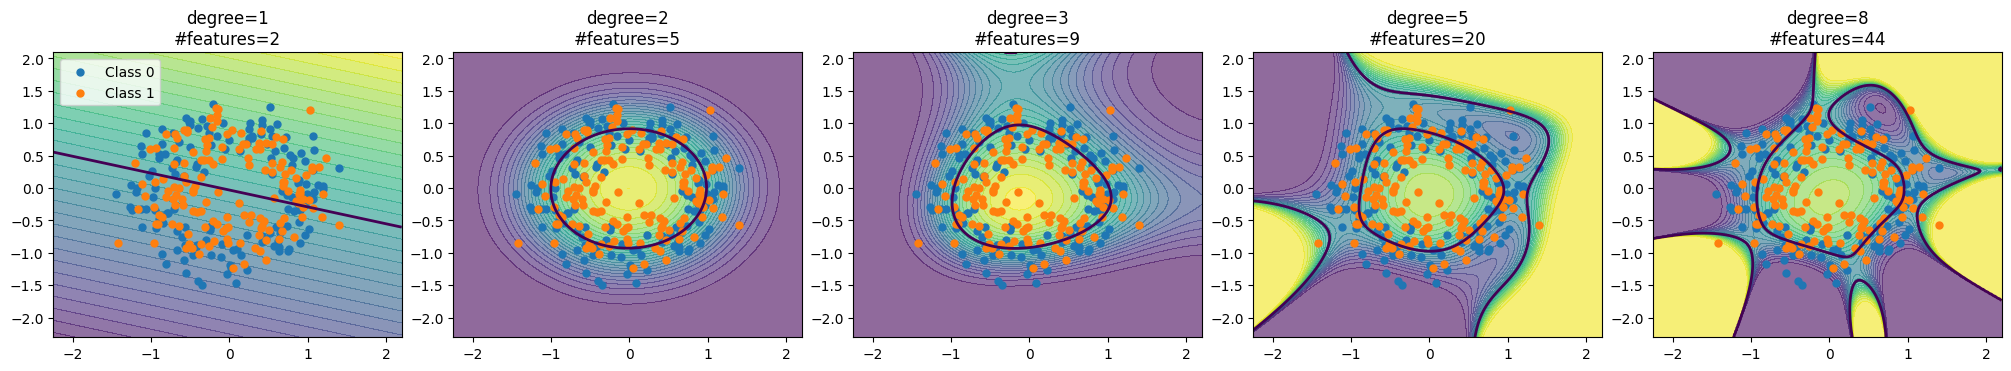

In [2]:
# ----------------------------
# 1) Data: 2D, non-linearly separable
# ----------------------------
X, y = make_circles(n_samples=300, noise=0.25, random_state=7)  # X: (N, 2)

# ----------------------------
# 2) Helper: plot decision boundary
# ----------------------------
def plot_decision_boundary(ax, model, X, y, title=""):
    # Grid over feature space
    x_min, x_max = X[:, 0].min() - 0.8, X[:, 0].max() + 0.8
    y_min, y_max = X[:, 1].min() - 0.8, X[:, 1].max() + 0.8
    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300),
    )
    grid = np.c_[xx.ravel(), yy.ravel()]  # (300*300, 2)

    # Predict probability for class 1 (works for logistic regression)
    proba = model.predict_proba(grid)[:, 1].reshape(xx.shape)

    # Background probability + contour at 0.5
    ax.contourf(xx, yy, proba, levels=30, alpha=0.6)
    ax.contour(xx, yy, proba, levels=[0.5], linewidths=2)

    # Points
    ax.scatter(X[y == 0, 0], X[y == 0, 1], s=25, label="Class 0")
    ax.scatter(X[y == 1, 0], X[y == 1, 1], s=25, label="Class 1")
    ax.set_title(title)
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)

# ----------------------------
# 3) Train models with different polynomial degrees
# ----------------------------
degrees = [1, 2, 3, 5, 8]  # 1 = plain linear model in original space

fig, axes = plt.subplots(1, len(degrees), figsize=(4 * len(degrees), 3.6), constrained_layout=True)

for ax, d in zip(axes, degrees):
    # Pipeline:
    # - PolynomialFeatures expands [x1, x2] into [1, x1, x2, x1^2, x1*x2, x2^2, ...]
    # - Standardize (important as degree grows)
    # - Logistic regression = linear classifier in expanded feature space
    model = Pipeline([
        ("poly", PolynomialFeatures(degree=d, include_bias=False)),
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=5000))
    ])

    model.fit(X, y)

    # Show how feature dimension grows with degree (for a 2D input)
    num_features = model.named_steps["poly"].fit_transform(X[:1]).shape[1]  # features after poly

    plot_decision_boundary(
        ax, model, X, y,
        title=f"degree={d}\n#features={num_features}"
    )

axes[0].legend(loc="upper left")
plt.show()

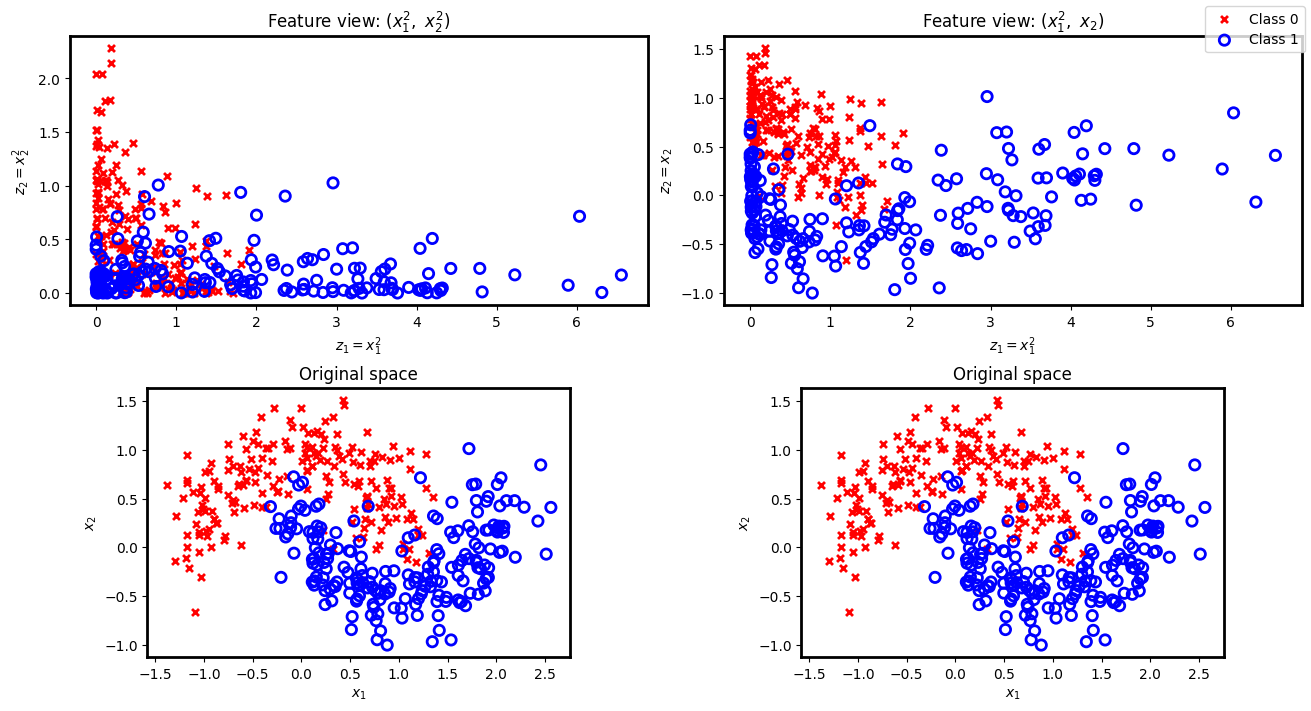

In [9]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_circles, make_moons
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LogisticRegression

# ----------------------------
# Choose dataset
# ----------------------------
DATASET = "moons"   # "circles" or "moons"

if DATASET == "circles":
    X, y = make_circles(n_samples=400, noise=0.08, factor=0.45, random_state=7)
    title_ds = "make_circles"
else:
    X, y = make_moons(n_samples=400, noise=0.25, random_state=7)
    title_ds = "make_moons"

x1, x2 = X[:, 0], X[:, 1] #[rows, columns]

# ----------------------------
# Helper: scatter/display
# ----------------------------
def scatter(ax, a, b, y, xlabel="", ylabel="", equal=True):
    ax.scatter(a[y == 0], b[y == 0], s=25, c="red", marker="x", linewidths=2, label="Class 0")
    ax.scatter(a[y == 1], b[y == 1], s=55, facecolors="none", edgecolors="blue", linewidths=2, label="Class 1")
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    if equal:
        ax.set_aspect("equal", adjustable="box")
    for spine in ax.spines.values():
        spine.set_linewidth(2)

# ----------------------------
# Helper: train linear model in polynomial space
# ----------------------------
def fit_poly_linear(X, y, degree):
    poly = PolynomialFeatures(degree=degree, include_bias=False)
    Xp = poly.fit_transform(X)  # (N, D)

    scaler = StandardScaler()
    Xp_s = scaler.fit_transform(Xp)

    clf = LogisticRegression(max_iter=5000)
    clf.fit(Xp_s, y)

    return poly, scaler, clf, Xp  # return Xp unscaled too (useful for plotting)

# ----------------------------
# Helper: decision boundary in original x-space
# (model is linear in poly-space, but boundary becomes nonlinear in x-space)
# ----------------------------
def plot_boundary_in_xspace(ax, X, y, poly, scaler, clf, title=""):
    x_min, x_max = X[:, 0].min() - 0.6, X[:, 0].max() + 0.6
    y_min, y_max = X[:, 1].min() - 0.6, X[:, 1].max() + 0.6
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 350),
                         np.linspace(y_min, y_max, 350))
    grid = np.c_[xx.ravel(), yy.ravel()]  # (M, 2)

    grid_p = poly.transform(grid)
    grid_p = scaler.transform(grid_p)
    proba = clf.predict_proba(grid_p)[:, 1].reshape(xx.shape)

    ax.contourf(xx, yy, proba, levels=30, alpha=0.6)
    ax.contour(xx, yy, proba, levels=[0.5], linewidths=2)
    scatter(ax, X[:, 0], X[:, 1], y, xlabel=r"$x_1$", ylabel=r"$x_2$", equal=True)
    ax.set_title(title)

# ----------------------------
# Pick two "feature coordinates" to visualize the transform
# This mimics your slide: show z1=x1^2 and z2=x2^2, etc.
# ----------------------------
def plot_feature_view(ax, X, y, which):
    x1, x2 = X[:, 0], X[:, 1]

    if which == "x":
        a, b = x1, x2
        xlabel, ylabel = r"$x_1$", r"$x_2$"
        t = "Original space"
        equal = True

    elif which == "x1^2_vs_x2":
        a, b = x1**2, x2
        xlabel, ylabel = r"$z_1=x_1^2$", r"$z_2=x_2$"
        t = r"Feature view: $(x_1^2,\ x_2)$"
        equal = False

    elif which == "x1^2_vs_x2^2":
        a, b = x1**2, x2**2
        xlabel, ylabel = r"$z_1=x_1^2$", r"$z_2=x_2^2$"
        t = r"Feature view: $(x_1^2,\ x_2^2)$"
        equal = False

    elif which == "radial_1d":
        # 1D: z = x1^2 + x2^2 - c
        c = 0.6 if DATASET == "circles" else 0.0  # circles: nice threshold; moons: not radial
        a = x1**2 + x2**2 - c
        b = np.zeros_like(a)
        xlabel, ylabel = r"$z = x_1^2 + x_2^2 - c$", ""
        t = r"1D feature: $z=x_1^2+x_2^2-c$"
        equal = False

    else:
        raise ValueError("Unknown feature view")

    scatter(ax, a, b, y, xlabel=xlabel, ylabel=ylabel, equal=equal)
    ax.set_title(t)
    if which == "radial_1d":
        ax.axvline(0.0, linewidth=3)
        ax.set_yticks([])

# ----------------------------
# Main: show varying degrees + how boundary changes
# ----------------------------
degrees = [2, 1]

fig, axes = plt.subplots(len(degrees), 2, figsize=(13, 3.5 * len(degrees)), constrained_layout=True)

for i, d in enumerate(degrees):
    poly, scaler, clf, Xp = fit_poly_linear(X, y, d)

    # Column 1: a "feature view" that exists for any dataset
    # (use x1^2 vs x2^2 once degree >=2; else show original)
    if d == 1:
        plot_feature_view(axes[i, 0], X, y, "x")
    else:
        plot_feature_view(axes[i, 0], X, y, "x1^2_vs_x2^2")

    # Column 2: another feature view (x1^2 vs x2) once degree >=2
    if d == 1:
        plot_feature_view(axes[i, 1], X, y, "x")
    else:
        plot_feature_view(axes[i, 1], X, y, "x1^2_vs_x2")



# Legend once
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right")
plt.show()
